# Model Zonal Velocity

In [8]:
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

## Import data files

In [9]:
dHe3_mean = xr.open_dataarray('data/P04_1989/dHe3_mean.nc')

dsE = xr.open_dataset('data/P04_1989/bottle_P04E_1989.nc')
dHe3 = dsE.delta_helium_3.dropna(dim='N_PROF', how='all')

In [10]:
MIN_PROFILE_DEPTH_M = 4600.0

# Approximate pressure in dbar as depth in metres; no conversion.
dHe3 = dsE.delta_helium_3.dropna(dim='N_PROF', how='all')
valid_samples = np.isfinite(dHe3) & np.isfinite(dHe3.pressure)
max_sample_depth_m = dHe3.pressure.where(valid_samples).max(dim='N_LEVELS')
dHe3 = dHe3.where(max_sample_depth_m >= MIN_PROFILE_DEPTH_M, drop=True)
if dHe3.sizes['N_PROF'] == 0:
    raise ValueError(f'No helium profiles reach {MIN_PROFILE_DEPTH_M:g} m')
print(f"Selected {dHe3.sizes['N_PROF']} helium profiles reaching at least {MIN_PROFILE_DEPTH_M:g} m")

Selected 4 helium profiles reaching at least 4600 m


In [11]:
output_dir = Path("data/cmip6_processed")

zonal_velocity_profiles = {}
for path in sorted((output_dir / "profiles").glob("*.nc")):
    with xr.open_dataset(path) as ds:
        zonal_velocity_profiles[path.stem] = ds["uo_mean_profile"].load()

model_sections = {}
for path in sorted((output_dir / "sections").glob("*.nc")):
    with xr.open_dataset(path) as ds:
        model_sections[path.stem] = ds.load()

In [12]:
def find_coordinate(data, candidates, standard_name):
    for name in candidates:
        if name in data.coords:
            return name
    for name, coordinate in data.coords.items():
        if coordinate.attrs.get("standard_name") == standard_name:
            return name
    raise KeyError(f"No {standard_name!r} coordinate found; available: {list(data.coords)}")

DEPTH_NAMES = ("lev", "olevel", "depth", "deptht", "z")

In [15]:
# NEW PLOT
# Plot a selected model ensemble mean and 95% interval with the P04E LADCP profile.
# Edit this list to choose which models contribute to the blue mean and interval.
EXCLUDED_MODELS = {"INM-CM5-0", "INM-CM4-8", "GISS-E2-1-H"}
plot_model_names = sorted(zonal_velocity_profiles)
ensemble_model_names = [
    model_name for model_name in plot_model_names
    if model_name not in EXCLUDED_MODELS
]

model_profiles = []
model_profile_names = []
model_max_depths = []
for model_name in ensemble_model_names:
    profile = zonal_velocity_profiles[model_name]
    depth_name = find_coordinate(profile, DEPTH_NAMES, "depth")
    model_depth = np.asarray(profile[depth_name].values, dtype=float)
    model_u = np.asarray(profile.values, dtype=float) * 100.0
    finite = np.isfinite(model_depth) & np.isfinite(model_u)
    if finite.sum() < 2:
        continue
    model_depth = model_depth[finite]
    model_u = model_u[finite]
    order = np.argsort(model_depth)
    model_depth = model_depth[order]
    model_u = model_u[order]
    unique_depth, unique_indices = np.unique(model_depth, return_index=True)
    model_profiles.append((unique_depth, model_u[unique_indices]))
    model_profile_names.append(model_name)
    model_max_depths.append(unique_depth[-1])

if not model_profiles:
    raise ValueError("No finite model profiles are available.")

common_max_depth = float(np.floor(min(model_max_depths) / 50.0) * 50.0)
common_depth = np.arange(0.0, common_max_depth + 50.0, 50.0)
interpolated_profiles = np.full((len(model_profiles), common_depth.size), np.nan)
for index, (model_depth, model_u) in enumerate(model_profiles):
    interpolated_profiles[index] = np.interp(common_depth, model_depth, model_u)

model_mean = np.nanmean(interpolated_profiles, axis=0)
model_lower = np.nanpercentile(interpolated_profiles, 2.5, axis=0)
model_upper = np.nanpercentile(interpolated_profiles, 97.5, axis=0)

## Velocity Profile

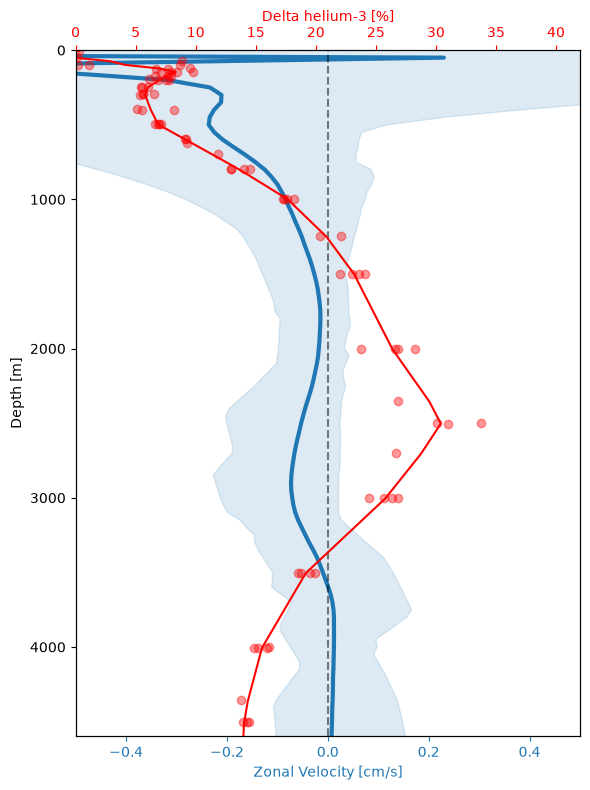

In [19]:
fig, ax = plt.subplots(figsize=(6, 8))
ax.plot(model_mean, common_depth, color="tab:blue", linewidth=3, label="Model mean")
ax.fill_betweenx(common_depth, 
                 model_lower, 
                 model_upper, 
                 color="tab:blue", 
                 alpha=0.15)
ax.axvline(0,color='k', alpha=0.5, linestyle='--')
ax.invert_yaxis()
ax.set_ylim(4600, 0)
ax.set_xlim(-0.5, 0.5)
ax.set_xlabel('Zonal Velocity [cm/s]', color='tab:blue')
ax.tick_params(axis='x', colors='tab:blue')
ax.set_ylabel('Depth [m]')

ax_helium = ax.twiny()
for i in range(dHe3.sizes['N_PROF']):
    profile = dHe3.isel(N_PROF=i)
    ax_helium.plot(profile, profile.pressure, marker='o', linestyle='', color='r', alpha=0.4)
ax_helium.plot(dHe3_mean, dHe3_mean.pressure, color='r', alpha=1)
ax_helium.set_xlabel('Delta helium-3 [%]', color='r')
ax_helium.tick_params(axis='x', colors='r')
ax_helium.set_xlim(0, 42)
fig.tight_layout()
plt.show()